# Experiment: Absolute vs. Relative Pacman Coordinates in Vector Representations

> **TL;DR**: Initially, switching to relative coordinates (`relative_to_pacman`) felt like a no-brainer to encourage translation invariance and better generalization across maps. However, testing across **10 independent random seeds** revealed the exact opposite: **Absolute coordinates decisively outperformed relative coordinates in game score, pellet clearing pace, and even zero-shot survival on unfamiliar maps.**

---

### Context & Initial Intuition
When designing flat vector observations for our Pacman agent, we explored two distinct coordinate frames:
- **Absolute Position (Default)**: The agent receives normalized (x, y) coordinates of Pacman and all 4 ghosts on the grid map.
- **Relative Position (`coordinates="relative_to_pacman"`)**: Ghost positions are expressed relative to Pacman's current location (as delta x and delta y offsets), while Pacman's own position is clamped to (0, 0).

Crucially, to keep the feature vector compact (47 dimensions) and training fast, **we do not provide explicit wall masks (`include_wall_mask=False`) or full pellet distribution maps (`include_pellet_mask=False`)**.

*The working hypothesis*: We expected relative coordinates to prevent the policy from overfitting to fixed grid coordinates, making it more resilient and transferable.

Here is the environment setup tested:

```python
# Environment builder for Flat Vector with relative coordinates
def make_vector_env(render_mode=None):
    return PacmanEnv(
        map_name="classic",
        obs_type="vector",
        obs_params={
            "coordinates": "relative_to_pacman",  # Key experimental variable
            "include_distances": True,
            "include_directions": True,
            "normalize": True,
        },
        reward_func=shared_event_reward,
        frame_skip=1,
        frame_stack=1,
        lives=1,
        render_mode=render_mode,
    )
```


---
## 1. Training Dynamics: Relative Coordinates (`relative_to_pacman`)

Here is how training progressed across seeds using relative coordinates:
- The mean game score and pellet completion rate climbed noticeably slowly.
- High variance between seeds; several seeds struggled to establish reliable ghost-evasion corridors.

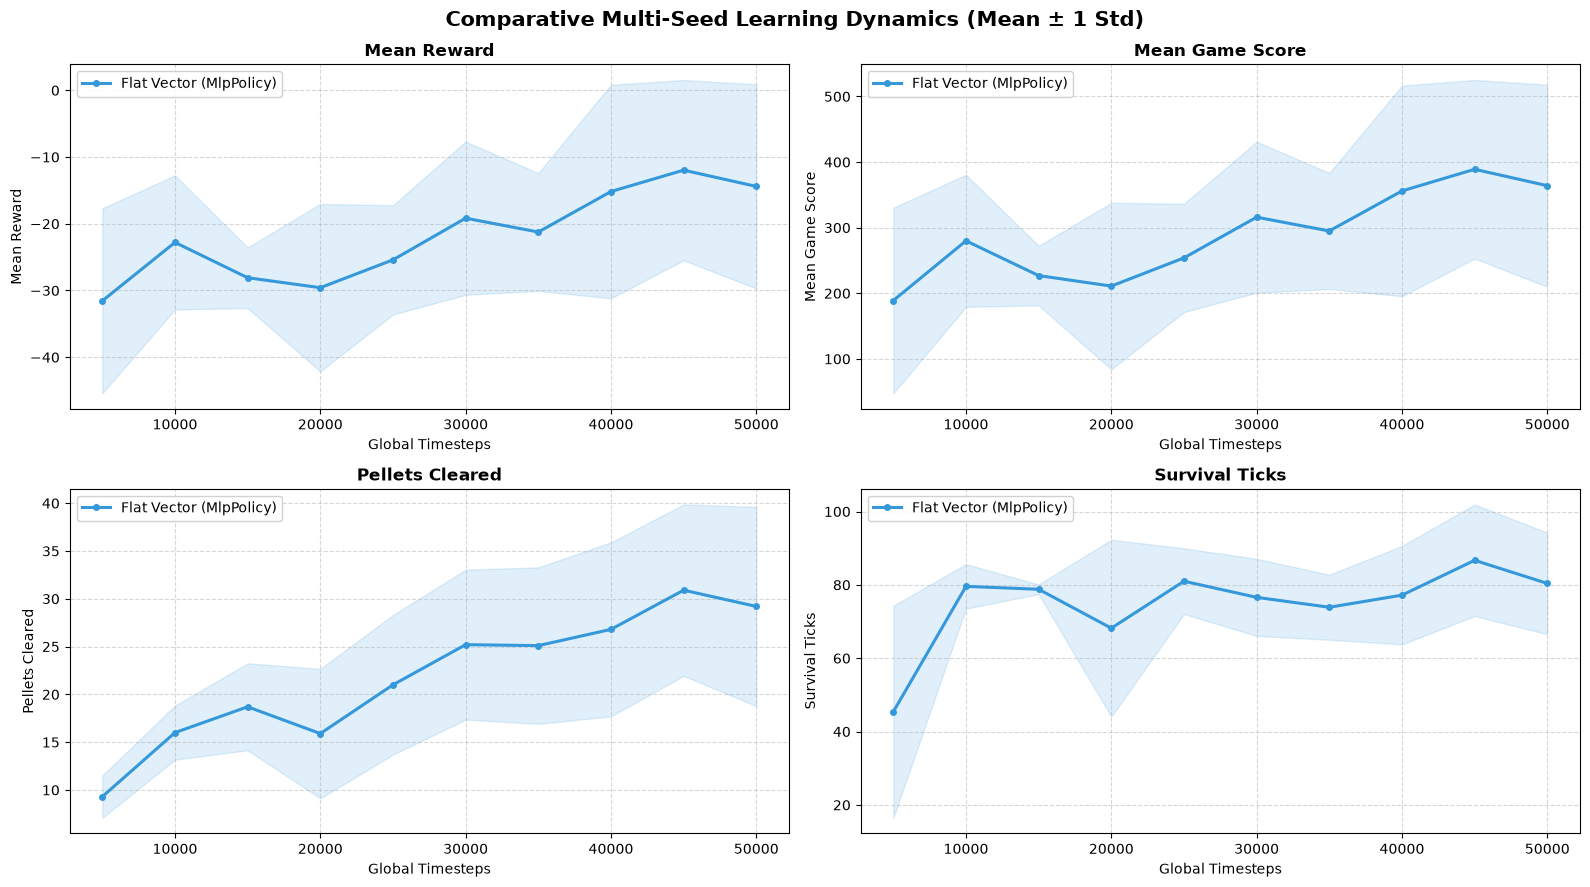


---
## 2. Training Dynamics: Absolute Coordinates (Default)

In contrast, here is the training trajectory when the agent retains its global (x, y) coordinates:
- The learning curve took off much faster and converged more smoothly.
- Mean game score and pellets cleared reached consistently higher levels across all seeds.

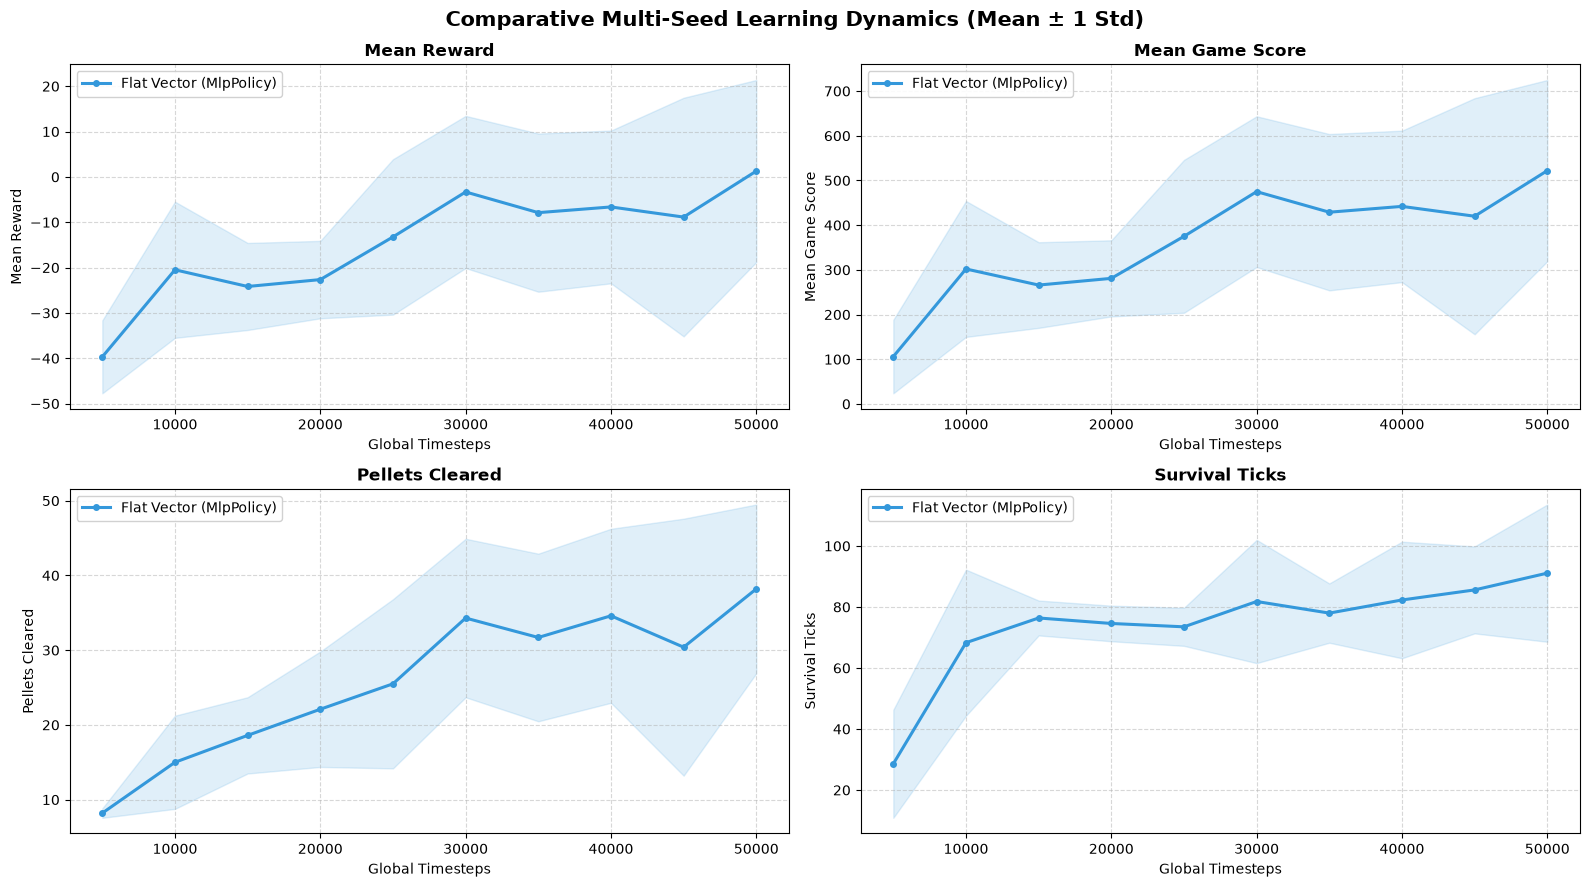


---
## 3. Quantitative Benchmark on Training Map (`classic`)

Evaluated across **10 random seeds** (each seed tested over multiple episodes; reported as Mean +/- Std):

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Representation</th>
      <th>Seed</th>
      <th>Mean Reward</th>
      <th>Mean Score</th>
      <th>Mean Pellets</th>
      <th>Mean Ticks</th>
      <th>Mean FPS</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Relative Position</td>
      <td>OVERALL (Mean +/- Std)</td>
      <td>-10.93 +/- 16.80</td>
      <td>399.0 +/- 169.1</td>
      <td>30.3 +/- 10.2</td>
      <td>82.5 +/- 14.5</td>
      <td>554.4</td>
    </tr>
    <tr>
      <th>0</th>
      <td>Absolute Position</td>
      <td>OVERALL (Mean +/- Std)</td>
      <td>1.76 +/- 15.76</td>
      <td>527.0 +/- 159.0</td>
      <td>40.3 +/- 8.0</td>
      <td>93.5 +/- 20.1</td>
      <td>915.6</td>
    </tr>
  </tbody>
</table>
</div>

### Quick Observations:
- **Game Score**: Absolute coordinates achieved **527.0 +/- 159.0**, outpacing Relative's **399.0 +/- 169.1** by over **32%**.
- **Pellets Cleared**: Absolute cleared an average of **40.3 pellets** compared to **30.3 pellets** for Relative.
- **Simulation Throughput (FPS)**: Absolute clocked in at **915.6 FPS**, significantly faster than **554.4 FPS** for Relative (due to the overhead of dynamically calculating relative offsets at every step).


---
## 4. Zero-Shot Transfer: Testing on an Unseen Map (`open_arena`)

This is where we anticipated relative coordinates might shine: evaluating checkpoints trained on `classic` directly on `open_arena` (an open 11x11 arena with no internal maze walls).

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Representation</th>
      <th>Eval Map</th>
      <th>Mean Reward</th>
      <th>Mean Score</th>
      <th>Mean Pellets</th>
      <th>Mean Ticks</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Relative Position</td>
      <td>open_arena</td>
      <td>-42.75 +/- 10.65</td>
      <td>74.0 +/- 108.6</td>
      <td>4.6 +/- 4.2</td>
      <td>15.2 +/- 25.0</td>
    </tr>
    <tr>
      <th>0</th>
      <td>Absolute Position</td>
      <td>open_arena</td>
      <td>-25.45 +/- 15.83</td>
      <td>251.0 +/- 161.8</td>
      <td>18.7 +/- 9.2</td>
      <td>55.0 +/- 38.6</td>
    </tr>
  </tbody>
</table>
</div>

### Reality Check:
- **Relative Coordinates suffered severe spatial disorientation**: Scores plummeted to **74.0 +/- 108.6**, clearing only **4.6 pellets** and dying within just **15.2 ticks** on average.
- **Absolute Coordinates adapted surprisingly well**: Kept an average score of **251.0 +/- 161.8**, collected **18.7 pellets**, and survived 3.6x longer (**55.0 ticks**).


---
## 5. Lessons Learned & Practical Takeaways

Why did relative coordinates fall short despite sounding so promising in theory?

1. **Absolute coordinates act as an implicit map lookup table**:
   - Because our 47-D vector does not feed raw wall layouts or full pellet grid locations to the policy, the agent has no explicit spatial blueprint of the maze.
   - Under **absolute coordinates**, `(pacman_row, pacman_col)` gives an exact, unambiguous index on the grid. Since the map is static, the MLP's hidden layers can easily memorize an implicit lookup table (which coordinates are walls, where corridors open up, and where pellet clusters reside). This gives absolute position an enormous head start early in training.
   - Under **relative coordinates**, Pacman's own coordinates are fixed to (0.0, 0.0). The agent is completely blind to where it is in the overall maze. It cannot directly correlate static walls or pellet patches with its position, so it must stumble through trial-and-error to infer maze geometry purely from transitions. That is why its early learning curves plateau so slowly.

2. **Pacman is fundamentally about static maze topology, not open-field pursuit**:
   - In a maze, knowing whether you are near a dead-end, an intersection, or an escape tunnel is critical for survival.
   - Relative coordinates induce "egocentric tunnel vision" - the agent knows where ghosts are relative to itself, but lacks global awareness of whether it is trapping itself in a blind alley.

3. **Topological distance features already capture relative proximity**:
   - Our vector representation already includes BFS shortest-path distances (`include_distances=True`).
   - The agent already knows the true path distance to every ghost and the nearest pellet. Forcing positional coordinates into relative offsets adds no new topological information, while breaking the fixed spatial reference frame that the MLP relies on.

4. **Rule of thumb for maze-based RL**:
   - Translating an intuitive idea (like translation invariance) into feature engineering can backfire when the problem structure is rooted in static spatial geometry.
   - Absolute coordinates (x, y) combined with shortest-path BFS distances remain the clear winner for our flat vector representation!
